<a href="https://colab.research.google.com/github/hngh262/BUSINFO_701_PROJECT-/blob/main/Technical_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1: Data Wrangling



## 1.1 	Data sources and selection

Three datasets were selected to investigate the relationship between movie characteristics, commercial performance, and Academy Award recognition.

### TMDB 5000 Movies

- **Source:** [TMDB 5000 Movie Dataset – Kaggle](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)
- **File:** `tmdb_5000_movies.csv`
- **Classification:** Client-provided dataset
- **Collection method:** Obtained from the data sources provided by the course lecturer.
- **Description and justification:** This dataset contains movie-level metadata, including production budgets, box office revenue, genres, release dates, and audience ratings. It was selected as the primary dataset because it provides the financial and descriptive information necessary to evaluate movie performance.

### TMDB 5000 Credits

- **Source:** [TMDB 5000 Movie Dataset – Kaggle](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)
- **File:** `tmdb_5000_credits.csv`
- **Classification:** Client-provided dataset
- **Collection method:** Obtained from the data sources provided by the course lecturer.
- **Description and justification**: This dataset provides cast and crew information associated with movies in the TMDB dataset. It was selected to investigate whether production talent, particularly directors, is associated with commercial performance and industry recognition.

### The Oscar Award

- **Source:** [The Oscar Award – Kaggle](https://www.kaggle.com/datasets/unanimad/the-oscar-award)
- **File:** `the_oscar_award.csv`
- **Classification:** Supplementary dataset
- **Collection method:** Downloaded separately by the project group in CSV format.
- **Description and justification:** This dataset contains historical Academy Award nominations and winner information. It was selected to complement the financial and audience-related information in the client-provided datasets with a measure of industry recognition.

### Summary

Together, the three datasets enable movie success to be examined from commercial, audience, and industry perspectives, providing a more comprehensive foundation for the subsequent analysis.

## 1.2 Data loading and general characteristics

The three datasets are stored in comma-separated values (CSV) format. The pandas library is used to import the datasets into DataFrames for inspection, cleaning, transformation and integration.

In [3]:
import pandas as pd
import json
base_url = (
    "https://raw.githubusercontent.com/"
    "hngh262/BUSINFO_701_PROJECT-/main/"
)

movies = pd.read_csv(base_url + "tmdb_5000_movies.csv")
credits = pd.read_csv(base_url + "tmdb_5000_credits.csv")
oscars = pd.read_csv(base_url + "the_oscar_award.csv")

### Dataset dimensions

In [4]:
print("Movies:", movies.shape)
print("Credits:", credits.shape)
print("Oscars:", oscars.shape)

Movies: (4803, 20)
Credits: (4803, 4)
Oscars: (11240, 8)


### Inspecting the dataset structure

In [5]:
movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [6]:
credits.head()

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [7]:
oscars.head()

,year_film,year_ceremony,ceremony,category,canon_category,name,film,winner
0,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Noose,False
1,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Patent Leather Kid,False
2,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Last Command,True
3,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Way of All Flesh,True
4,1927,1928,1,ACTRESS,ACTRESS IN A LEADING ROLE,Louise Dresser,A Ship Comes In,False


In [8]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

In [9]:
credits.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  4803 non-null   int64
 1   title     4803 non-null   str  
 2   cast      4803 non-null   str  
 3   crew      4803 non-null   str  
dtypes: int64(1), str(3)
memory usage: 33.8 MB


In [10]:
oscars.info()

<class 'pandas.DataFrame'>
RangeIndex: 11240 entries, 0 to 11239
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   year_film       11240 non-null  int64 
 1   year_ceremony   11240 non-null  int64 
 2   ceremony        11240 non-null  int64 
 3   category        11240 non-null  str   
 4   canon_category  11240 non-null  str   
 5   name            11228 non-null  str   
 6   film            10877 non-null  str   
 7   winner          11235 non-null  object
dtypes: int64(3), object(1), str(4)
memory usage: 1.5+ MB


Although all three datasets are stored in CSV format, their internal structures differ. The Movies and Credits datasets represent individual movies, whereas the Oscar dataset may contain multiple records for the same movie because a film can be nominated in multiple award categories.

Furthermore, several columns in the TMDB datasets contain JSON-formatted strings representing nested information such as genres, cast members and crew members. These fields require additional processing before they can be used for analysis.

## 1.3 Initial data quality audit

### Missing values

Missing values were examined to identify incomplete records and determine appropriate treatment strategies before integrating the datasets.

In [11]:
movies.isnull().sum()

budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64

In [12]:
credits.isnull().sum()

movie_id    0
title       0
cast        0
crew        0
dtype: int64

In [13]:
oscars.isnull().sum()

year_film           0
year_ceremony       0
ceremony            0
category            0
canon_category      0
name               12
film              363
winner              5
dtype: int64

### Duplicate records

In [14]:
print("Movies duplicates:", movies.duplicated().sum())
print("Credits duplicates:", credits.duplicated().sum())
print("Oscars duplicates:", oscars.duplicated().sum())

Movies duplicates: 0
Credits duplicates: 0
Oscars duplicates: 6


In [15]:
# Check whether the movie identifiers are unique.

print("Duplicate movie IDs:",
      movies['id'].duplicated().sum())

print("Duplicate credit movie IDs:",
      credits['movie_id'].duplicated().sum())

Duplicate movie IDs: 0
Duplicate credit movie IDs: 0


### Invalid financial values

Zero-valued budgets and revenues may represent unavailable financial information. Treating these records as genuine zero-dollar amounts could distort financial performance calculations.

In [16]:
print("Zero or negative budgets:",
      (movies['budget'] <= 0).sum())

print("Zero or negative revenues:",
      (movies['revenue'] <= 0).sum())

Zero or negative budgets: 1037
Zero or negative revenues: 1427


### Nested data fields

In [17]:
# Inspect the original JSON-formatted strings before extracting relevant information.

print(movies['genres'].iloc[0])
print(credits['crew'].iloc[0][:1000])

[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "name": "Science Fiction"}]
[{"credit_id": "52fe48009251416c750aca23", "department": "Editing", "gender": 0, "id": 1721, "job": "Editor", "name": "Stephen E. Rivkin"}, {"credit_id": "539c47ecc3a36810e3001f87", "department": "Art", "gender": 2, "id": 496, "job": "Production Design", "name": "Rick Carter"}, {"credit_id": "54491c89c3a3680fb4001cf7", "department": "Sound", "gender": 0, "id": 900, "job": "Sound Designer", "name": "Christopher Boyes"}, {"credit_id": "54491cb70e0a267480001bd0", "department": "Sound", "gender": 0, "id": 900, "job": "Supervising Sound Editor", "name": "Christopher Boyes"}, {"credit_id": "539c4a4cc3a36810c9002101", "department": "Production", "gender": 1, "id": 1262, "job": "Casting", "name": "Mali Finn"}, {"credit_id": "5544ee3b925141499f0008fc", "department": "Sound", "gender": 2, "id": 1729, "job": "Original Music Composer", "name": "James Horner"}, {"cr


### Potential Integration Problems

The following potential data quality and integration issues were identified for investigation before combining the three datasets.

| Potential Issue | Dataset Affected | Proposed Treatment |
|---|---|---|
| Missing financial information | Movies | Treat invalid financial values as missing values. |
| Nested JSON strings | Movies and Credits | Parse JSON-formatted strings using `json.loads()`. |
| Inconsistent movie titles | Movies and Oscars | Standardise movie title formatting. |
| Different date formats | Movies and Oscars | Extract and standardise film release years. |
| Multiple records per movie | Oscars | Aggregate nomination and winner records at the movie level. |
| Missing film titles | Oscars | Exclude records without valid film titles from movie-level matching. |
| Different historical coverage | Movies and Oscars | Examine and validate overlapping film years. |

These potential issues will inform the data cleaning and transformation procedures described in Section 1.4 to ensure data consistency, accuracy, and reliability before integration.


## 1.4 Individual dataset cleaning and transformation

### Movies dataset

The Movies dataset was prepared by removing duplicate records, standardising release dates and movie titles, extracting genre information and creating financial performance variables.

In [18]:
# Step 1: Remove exact duplicates

movies = movies.drop_duplicates().copy()

In [19]:
# Step 2: Convert release dates

movies['release_date'] = pd.to_datetime(
    movies['release_date'],
    errors='coerce'
)

movies['release_year'] = movies['release_date'].dt.year

In [20]:
# Step 3: Standardise movie titles

movies['title_key'] = (
    movies['title']
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# The original movie title is retained for reporting purposes, while title_key is created specifically for matching.

In [21]:
# Step 4: Extract genres

def extract_genres(value):
    if pd.isna(value):
        return []

    genre_list = []

    for genre in json.loads(value):
        genre_list.append(genre['name'])

    return genre_list

In [22]:
movies['genre_list'] = movies['genres'].apply(extract_genres)

movies[['title', 'genre_list']].head()

# A movie can belong to multiple genres, so we retain all its genre classifications.

,title,genre_list
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]"
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]"
2,Spectre,"[Action, Adventure, Crime]"
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]"
4,John Carter,"[Action, Adventure, Science Fiction]"


In [23]:
# Step 5: Treat invalid financial values

movies.loc[movies['budget'] <= 0, 'budget'] = None

movies.loc[movies['revenue'] <= 0, 'revenue'] = None

# Rather than removing movies with missing financial information, we retain them for other types of analysis.

In [24]:
# Step 6: Calculate financial performance metrics

movies['estimated_profit'] = (
    movies['revenue'] - movies['budget']
)

movies['roi'] = (
    movies['estimated_profit'] / movies['budget']
) * 100

In [25]:
movies[['title', 'budget', 'revenue',
        'estimated_profit', 'roi']].head()

# Estimated profit is a proxy for financial performance because additional costs, including marketing and distribution expenses, are not included.

,title,budget,revenue,estimated_profit,roi
0,Avatar,237000000.0,2.787965e+09,2.550965e+09,1076.356577
1,Pirates of the Caribbean: At World's End,300000000.0,9.610000e+08,6.610000e+08,220.333333
2,Spectre,245000000.0,8.806746e+08,6.356746e+08,259.459024
3,The Dark Knight Rises,250000000.0,1.084939e+09,8.349391e+08,333.975640
4,John Carter,260000000.0,2.841391e+08,2.413910e+07,9.284269


### Credits dataset

The Credits dataset contains nested cast and crew information. The relevant production talent information was extracted to facilitate subsequent analysis.

In [26]:
# Step 1: Remove exact duplicates

credits = credits.drop_duplicates().copy()

In [27]:
# Step 2: Extract directors

def extract_directors(value):
    if pd.isna(value):
        return []

    directors = []

    for person in json.loads(value):
        if person['job'] == 'Director':
            directors.append(person['name'])

    return directors

In [28]:
credits['directors'] = credits['crew'].apply(
    extract_directors
)

credits[['title', 'directors']].head()

,title,directors
0,Avatar,[James Cameron]
1,Pirates of the Caribbean: At World's End,[Gore Verbinski]
2,Spectre,[Sam Mendes]
3,The Dark Knight Rises,[Christopher Nolan]
4,John Carter,[Andrew Stanton]


In [29]:
# Step 3: Extract cast members

def extract_cast(value):
    if pd.isna(value):
        return []

    cast_members = []

    for person in json.loads(value):
        cast_members.append(person['name'])

    return cast_members

In [30]:
credits['cast_members'] = credits['cast'].apply(
    extract_cast
)

In [31]:
# Step 4: Select relevant columns

credits_clean = credits[
    ['movie_id', 'directors', 'cast_members']
].copy()

credits_clean.head()

# The original nested fields are excluded from the prepared credits dataset because the information required for analysis has already been extracted.

,movie_id,directors,cast_members
0,19995,[James Cameron],"[Sam Worthington, Zoe Saldana, Sigourney Weave..."
1,285,[Gore Verbinski],"[Johnny Depp, Orlando Bloom, Keira Knightley, ..."
2,206647,[Sam Mendes],"[Daniel Craig, Christoph Waltz, Léa Seydoux, R..."
3,49026,[Christopher Nolan],"[Christian Bale, Michael Caine, Gary Oldman, A..."
4,49529,[Andrew Stanton],"[Taylor Kitsch, Lynn Collins, Samantha Morton,..."


### Oscar dataset

The Oscar dataset requires additional transformation because its unit of observation is an award nomination rather than an individual movie. Nomination records are therefore aggregated at the movie level before integration.

In [32]:
# Step 1: Remove exact duplicates and missing matching keys

oscars = oscars.drop_duplicates().copy()

oscars = oscars.dropna(
    subset=['film', 'year_film']
)

In [33]:
# Step 2: Standardise movie titles

oscars['title_key'] = (
    oscars['film']
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

In [34]:
# Step 3: Standardise film year

oscars['year_film'] = pd.to_numeric(
    oscars['year_film'],
    errors='coerce'
)

oscars = oscars.dropna(subset=['year_film'])

oscars['year_film'] = oscars['year_film'].astype(int)

# We use the film year instead of the ceremony year because Oscar ceremonies typically take place after the relevant film release year.

In [35]:
# Step 4: Inspect and standardise the winner field

oscars['winner'].value_counts(dropna=False)

winner
False    8603
True     2263
NaN         5
Name: count, dtype: int64

In [36]:
oscars['winner_flag'] = (
    oscars['winner']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'true': 1, 'false': 0})
)

oscars['winner_flag'].isnull().sum()

np.int64(5)

In [37]:
# Step 5: Aggregate Oscar records

oscars_summary = (
    oscars.groupby(['title_key', 'year_film'])
    .agg(
        oscar_nominations=('winner_flag', 'size'),
        oscar_wins=('winner_flag', 'sum')
    )
    .reset_index()
)

In [38]:
oscars_summary.head()

# This transformation prevents individual TMDB movies from being duplicated during the merge.

,title_key,year_film,oscar_nominations,oscar_wins
0,"$1,000 a minute",1935,1,0.0
1,'38',1986,1,0.0
2,'crocodile' dundee,1986,1,0.0
3,'round midnight,1986,2,1.0
4,(a) torzija [(a) torsion],2003,1,0.0


## 1.5 Data integration

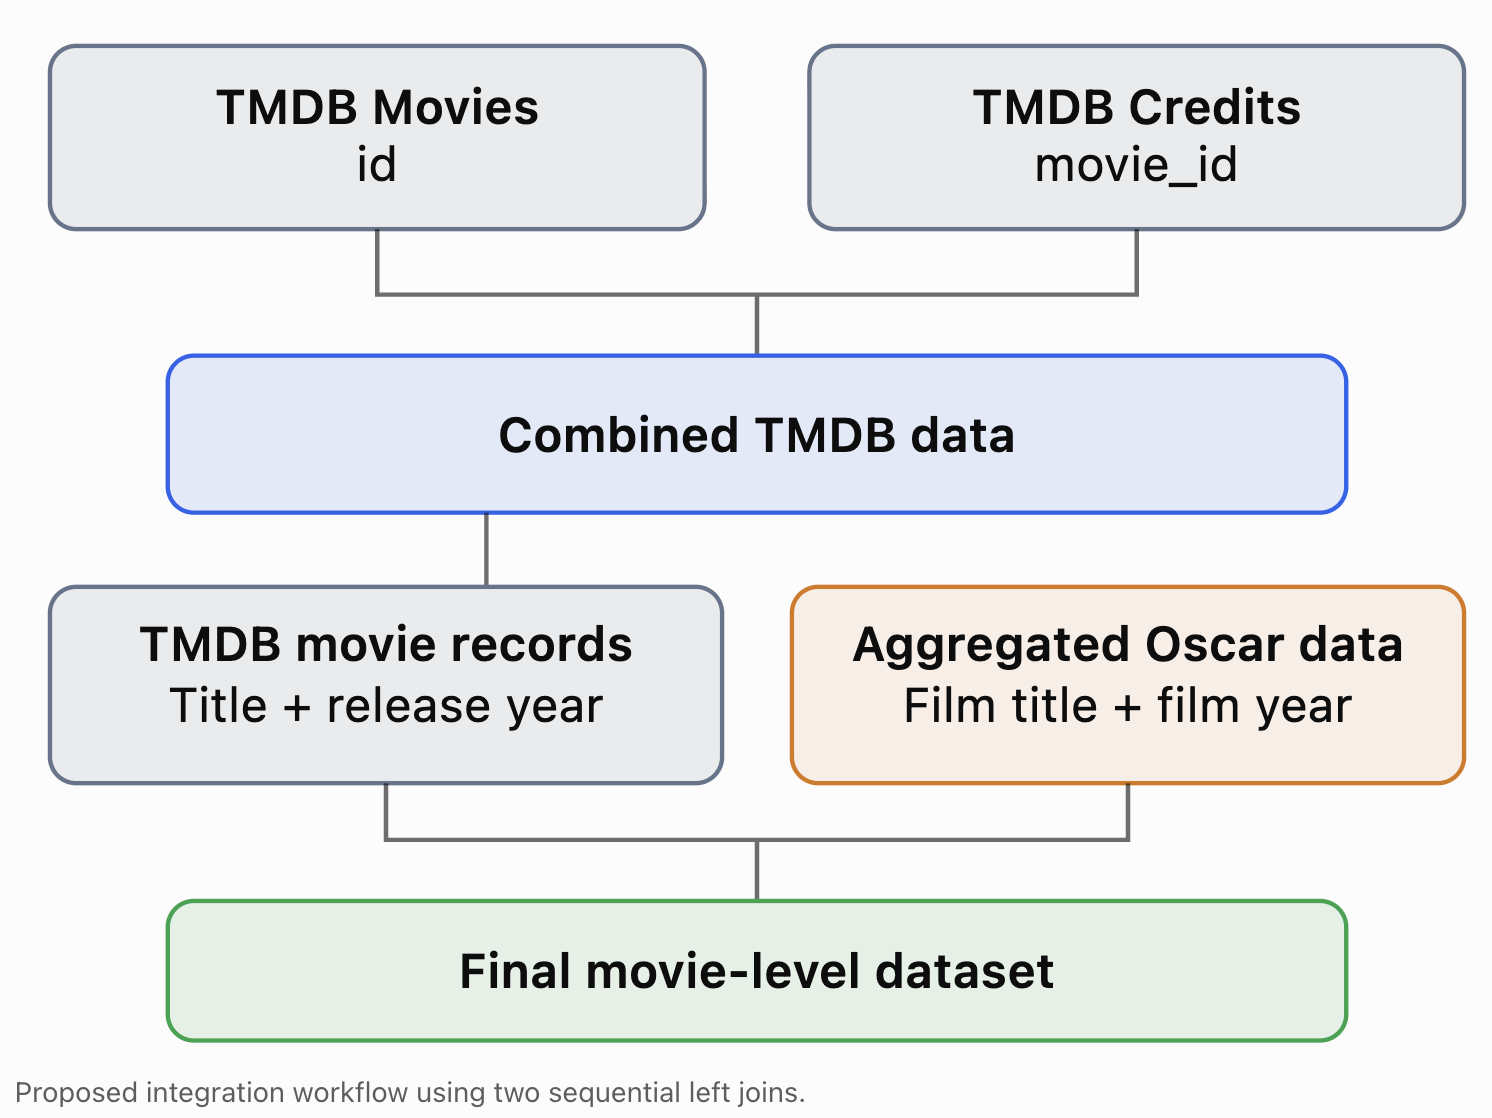

### Combining Movies and Credits

The Movies and Credits datasets share a common movie identifier. A left join is performed using id from the Movies dataset and movie_id from the Credits dataset.

In [39]:
movies_credits = pd.merge(
    movies,
    credits_clean,
    left_on='id',
    right_on='movie_id',
    how='left',
    validate='one_to_one',
    indicator=True
)

In [40]:
movies_credits['_merge'].value_counts()

_merge
both          4803
left_only        0
right_only       0
Name: count, dtype: int64

In [41]:
movies_credits.shape

(4803, 29)

In [42]:
movies_credits = movies_credits.drop(columns='_merge')

### Combining TMDB and Oscar data

Unlike the two TMDB datasets, Oscar records do not contain TMDB movie identifiers. Therefore, standardised movie titles and film years are used as a composite matching key.

In [43]:
# First, we check for ambiguous movie titles within the same release year.

movies_credits[
    movies_credits.duplicated(
        subset=['title_key', 'release_year'],
        keep=False
    )
][['id', 'title', 'release_year']]

,id,title,release_year


In [44]:
combined = pd.merge(
    movies_credits,
    oscars_summary,
    left_on=['title_key', 'release_year'],
    right_on=['title_key', 'year_film'],
    how='left',
    validate='many_to_one',
    indicator=True
)

In [45]:
combined['_merge'].value_counts()

_merge
left_only     3936
both           867
right_only       0
Name: count, dtype: int64

### Assessing the Oscar matching results

In [46]:
matched = (combined['_merge'] == 'both').sum()

match_rate = matched / len(combined) * 100

print("Number of matched movies:", matched)
print("Percentage of matched movies:", round(match_rate, 2))

# Note that the match rate does not represent matching accuracy. Many films will legitimately have no Oscar nominations.

Number of matched movies: 867
Percentage of matched movies: 18.05


In [47]:
# We should also inspect unmatched records to identify possible title or year discrepancies.

combined.loc[
    combined['_merge'] == 'left_only',
    ['title', 'release_year']
].head(20)

,title,release_year
3,The Dark Knight Rises,2012.0
4,John Carter,2012.0
5,Spider-Man 3,2007.0
7,Avengers: Age of Ultron,2015.0
9,Batman v Superman: Dawn of Justice,2016.0
11,Quantum of Solace,2008.0
14,Man of Steel,2013.0
15,The Chronicles of Narnia: Prince Caspian,2008.0
16,The Avengers,2012.0
17,Pirates of the Caribbean: On Stranger Tides,2011.0


A particularly important consideration is that an unmatched movie does not automatically mean that it has never received an Oscar nomination.

After validating the matching quality and historical coverage, we can replace missing nomination and win counts with zero for eligible movies. Until then, I suggest retaining missing values and distinguishing successful matches explicitly.

In [48]:
combined['oscar_match'] = combined['_merge'] == 'both'

## 1.6 	Final dataset validation

Following data integration, the combined dataset is validated to ensure that the merging process preserves the original movie-level structure and produces logically consistent award information.

In [49]:
# Check the number of records

print("Original movie records:", len(movies))
print("Combined movie records:", len(combined))

Original movie records: 4803
Combined movie records: 4803


In [50]:
# Check the uniqueness of movie IDs

print("Duplicate movie IDs:",
      combined['id'].duplicated().sum())

Duplicate movie IDs: 0


In [51]:
# Check Oscar wins against nominations

print(
    "Invalid Oscar records:",
    (combined['oscar_wins'] >
     combined['oscar_nominations']).sum()
)

Invalid Oscar records: 0


In [52]:
# Confirm data integrity

assert len(combined) == len(movies)

assert combined['id'].is_unique

assert not (
    combined['oscar_wins'] >
    combined['oscar_nominations']
).any()

In [53]:
# Inspect the integrated dataset

combined[
    ['id', 'title', 'release_year', 'genre_list',
     'directors', 'budget', 'revenue', 'roi',
     'oscar_nominations', 'oscar_wins', 'oscar_match']
].head(10)

,id,title,release_year,genre_list,directors,budget,revenue,roi,oscar_nominations,oscar_wins,oscar_match
0,19995,Avatar,2009.0,"[Action, Adventure, Fantasy, Science Fiction]",[James Cameron],237000000.0,2.787965e+09,1076.356577,9.0,3.0,True
1,285,Pirates of the Caribbean: At World's End,2007.0,"[Adventure, Fantasy, Action]",[Gore Verbinski],300000000.0,9.610000e+08,220.333333,2.0,0.0,True
2,206647,Spectre,2015.0,"[Action, Adventure, Crime]",[Sam Mendes],245000000.0,8.806746e+08,259.459024,1.0,1.0,True
3,49026,The Dark Knight Rises,2012.0,"[Action, Crime, Drama, Thriller]",[Christopher Nolan],250000000.0,1.084939e+09,333.975640,NaN,NaN,False
4,49529,John Carter,2012.0,"[Action, Adventure, Science Fiction]",[Andrew Stanton],260000000.0,2.841391e+08,9.284269,NaN,NaN,False
5,559,Spider-Man 3,2007.0,"[Fantasy, Action, Adventure]",[Sam Raimi],258000000.0,8.908716e+08,245.299080,NaN,NaN,False
6,38757,Tangled,2010.0,"[Animation, Family]","[Byron Howard, Nathan Greno]",260000000.0,5.917949e+08,127.613437,1.0,0.0,True
7,99861,Avengers: Age of Ultron,2015.0,"[Action, Adventure, Science Fiction]",[Joss Whedon],280000000.0,1.405404e+09,401.929891,NaN,NaN,False
8,767,Harry Potter and the Half-Blood Prince,2009.0,"[Adventure, Fantasy, Family]",[David Yates],250000000.0,9.339592e+08,273.583679,1.0,0.0,True
9,209112,Batman v Superman: Dawn of Justice,2016.0,"[Action, Adventure, Fantasy]",[Zack Snyder],250000000.0,8.732602e+08,249.304078,NaN,NaN,False


In [54]:
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   budget                3766 non-null   float64       
 1   genres                4803 non-null   str           
 2   homepage              1712 non-null   str           
 3   id                    4803 non-null   int64         
 4   keywords              4803 non-null   str           
 5   original_language     4803 non-null   str           
 6   original_title        4803 non-null   str           
 7   overview              4800 non-null   str           
 8   popularity            4803 non-null   float64       
 9   production_companies  4803 non-null   str           
 10  production_countries  4803 non-null   str           
 11  release_date          4802 non-null   datetime64[us]
 12  revenue               3376 non-null   float64       
 13  runtime               4801 no

## 1.7 Final data storage

The final integrated dataset is stored in CSV format, providing a portable and widely accessible data store that can be imported into pandas and other analytical tools.

List-valued fields are converted into JSON strings to preserve their structure when exporting the DataFrame.

In [55]:
final_movies = combined[
    ['id', 'title', 'release_year', 'genre_list',
     'directors', 'cast_members', 'budget', 'revenue',
     'estimated_profit', 'roi', 'vote_average',
     'vote_count', 'runtime', 'oscar_nominations',
     'oscar_wins', 'oscar_match']
].copy()

In [56]:
for column in ['genre_list', 'directors', 'cast_members']:
    final_movies[column] = final_movies[column].apply(
        lambda value: json.dumps(value)
        if isinstance(value, list) else None
    )

In [57]:
final_movies.to_csv(
    'combined_movie_data.csv',
    index=False
)

In [58]:
final_check = pd.read_csv('combined_movie_data.csv')

final_check.shape

(4803, 16)

In [59]:
assert final_check.shape == final_movies.shape

The final integrated dataset is available for inspection and reproduction at the following Google Drive link: